In [1]:
import numpy as np
import os

A = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
A_genes = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True)
A_tfs   = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_tfs.npy", allow_pickle=True)

print(A.shape)

import anndata as ad

adata = ad.read_h5ad("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad")
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
gene_names = list(adata.var_names)
gene_to_idx = {g: i for i, g in enumerate(gene_names)}

(277, 2995)


In [2]:
# ALIGNMENT BLOCK (KEEP AS IS)
tf_mask = np.array([tf in gene_to_idx for tf in A_tfs])
A = A[tf_mask, :]
A_tfs = A_tfs[tf_mask]

tf_idx = np.array([gene_to_idx[tf] for tf in A_tfs])

gene_mask = np.array([g in gene_to_idx for g in A_genes])
A = A[:, gene_mask]
A_genes = A_genes[gene_mask]

gene_idx = np.array([gene_to_idx[g] for g in A_genes])

X = X_full[:, gene_idx]

subset_gene_names = np.array(A_genes)
subset_gene_to_idx = {g: i for i, g in enumerate(subset_gene_names)}

tf_idx = np.array([
    subset_gene_to_idx[tf]
    for tf in A_tfs
    if tf in subset_gene_to_idx
])

tf_mask = np.array([tf in subset_gene_to_idx for tf in A_tfs])

A = A[tf_mask, :]
A_tfs = A_tfs[tf_mask]

tf_idx = np.array([subset_gene_to_idx[tf] for tf in A_tfs])

X_TF = X[:, tf_idx]

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

X_t = torch.tensor(X, dtype=torch.float32)
X_TF_t = torch.tensor(X_TF, dtype=torch.float32)

In [4]:
pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X)

nn_model = NearestNeighbors(n_neighbors=30)
nn_model.fit(X_pca)
nn_idx = nn_model.kneighbors(X_pca, return_distance=False)

nn_idx_t = torch.tensor(nn_idx, dtype=torch.long)

In [5]:
class RegulatoryFlowModel(nn.Module):
    def __init__(self, G, T, K):
        super().__init__()
        self.U = nn.Parameter(torch.randn(G, K) * 0.01)
        self.V = nn.Parameter(torch.randn(T, K) * 0.01)

    def forward(self, X_TF):
        A = self.U @ self.V.T
        V_pred = X_TF @ A.T
        return V_pred, A

In [6]:
def cosine_alignment_loss(V_pred, X_t, nn_idx_t):
    v_norm = F.normalize(V_pred, dim=1)

    total_loss = 0.0
    K_nn = nn_idx_t.shape[1]

    for k in range(K_nn):
        neighbors = nn_idx_t[:, k]
        delta = X_t[neighbors] - X_t

        delta_norm = F.normalize(delta, dim=1)
        cos = (v_norm * delta_norm).sum(dim=1)

        total_loss += -cos.mean()

    return total_loss / K_nn

In [7]:
K = 20
model = RegulatoryFlowModel(G=X.shape[1], T=X_TF.shape[1], K=K)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(300):
    optimizer.zero_grad()

    V_pred, A_learned = model(X_TF_t)

    loss_align = cosine_alignment_loss(V_pred, X_t, nn_idx_t)
    loss_reg = 1e-3 * (model.U.pow(2).mean() + model.V.pow(2).mean())

    loss = loss_align + loss_reg

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

    if epoch % 30 == 0:
        print(epoch, loss.item())

0 -0.0004471908323466778
30 -0.20744673907756805
60 -0.27804696559906006
90 -0.30706095695495605
120 -0.31841546297073364
150 -0.3225499987602234
180 -0.32517364621162415
210 -0.3267585337162018
240 -0.3277340829372406
270 -0.32844385504722595


In [8]:
with torch.no_grad():
    V_pred, A_learned = model(X_TF_t)

np.save("uv_no_mask/V_pred_learned.npy", V_pred.numpy())
np.save("uv_no_mask/A_learned.npy", A_learned.numpy())
np.save("uv_no_mask/U.npy", model.U.detach().numpy())
np.save("uv_no_mask/V.npy", model.V.detach().numpy())

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


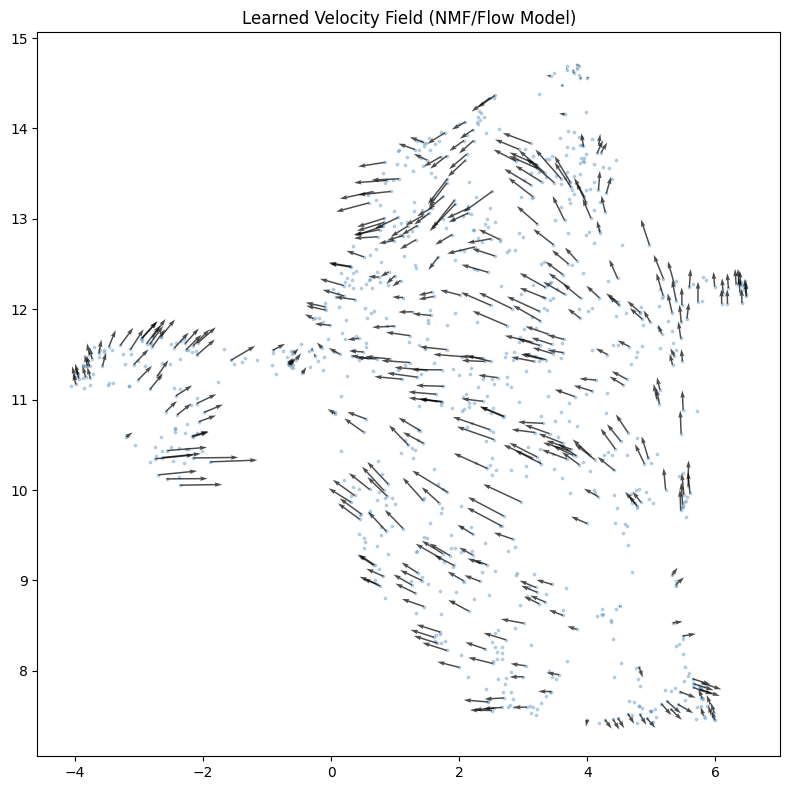

Velocity–pseudotime alignment: 0.14433533520101186


In [9]:
# visualize_velocity.py (UPDATED FOR LEARNED MODEL)

import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

# =========================
# 1. LOAD DATA
# =========================
adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("uv_no_mask/V_pred_learned.npy")   # <-- UPDATED NAME
gene_idx = np.load("gene_idx.npy")

X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

# =========================
# 2. ALIGN X TO MODEL SPACE
# =========================
X = X_full[:, gene_idx]

assert X.shape == V_pred.shape, "Mismatch between X and V_pred"

# =========================
# 3. UMAP EMBEDDING
# =========================
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# =========================
# 4. PROJECT VELOCITY TO UMAP
# =========================
eps = 0.5

X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# =========================
# 5. SMOOTH VELOCITY FIELD
# =========================
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# =========================
# 6. PLOT VECTOR FIELD
# =========================
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Learned Velocity Field (NMF/Flow Model)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

# =========================================================
# 7. FIXED CORRELATION (IMPORTANT — YOUR OLD ONE WAS WRONG)
# =========================================================

# WRONG BEFORE:
# spearmanr(pseudotime, dot(V, X[i+1] - X[i]))

# CORRECT IDEA:
# does velocity align with actual transitions in pseudotime ordering?

pseudo = adata.obs["facs_pseudotime"].values

# sort by pseudotime
order = np.argsort(pseudo)

X_sorted = X[order]
V_sorted = V_pred[order]

# finite differences along trajectory
dX = X_sorted[1:] - X_sorted[:-1]
V_mid = V_sorted[:-1]

# alignment score (cosine-like dot product)
alignment = np.sum(V_mid * dX, axis=1)

score = spearmanr(pseudo[order][:-1], alignment)[0]

print("Velocity–pseudotime alignment:", score)

In [10]:
cos_sim = np.sum(V_mid * dX, axis=1) / (
    np.linalg.norm(V_mid, axis=1) * np.linalg.norm(dX, axis=1) + 1e-8
)

print("Mean velocity alignment:", np.mean(cos_sim))

Mean velocity alignment: 0.30647498


In [11]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

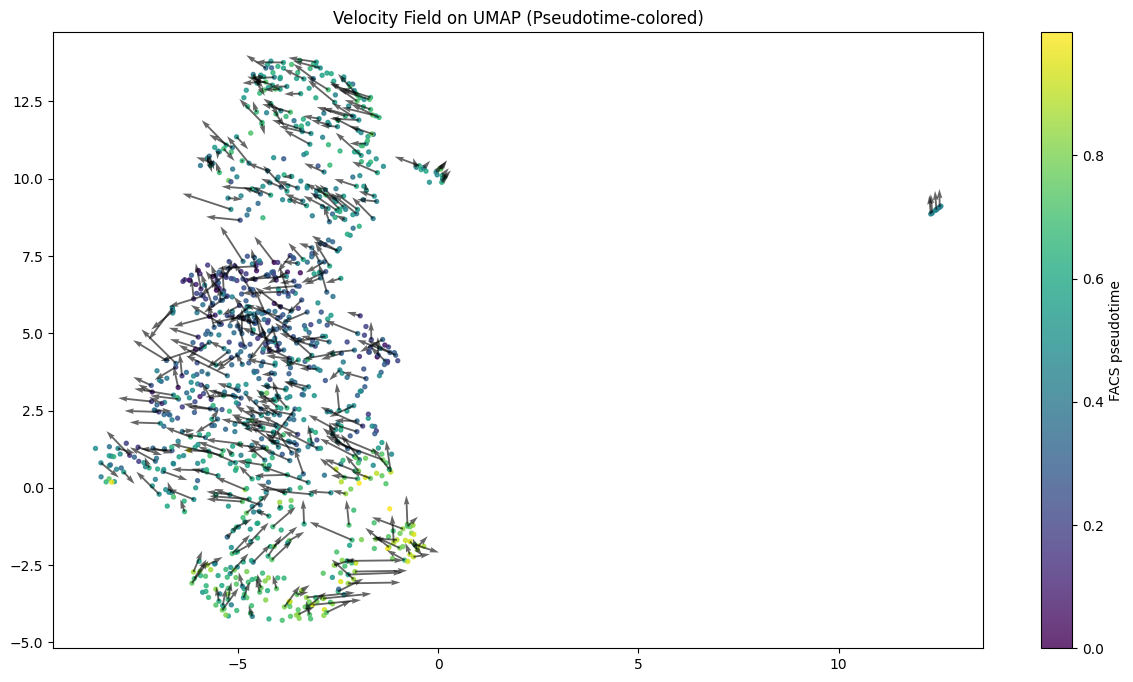

In [13]:
import numpy as np
import matplotlib.pyplot as plt

X_umap = adata.obsm["X_umap"]

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    color="black", alpha=0.6, scale=10, width=0.002
)

ax.set_title("Velocity Field on UMAP (Pseudotime-colored)")
plt.show()

IndexError: index 1020 is out of bounds for axis 0 with size 991

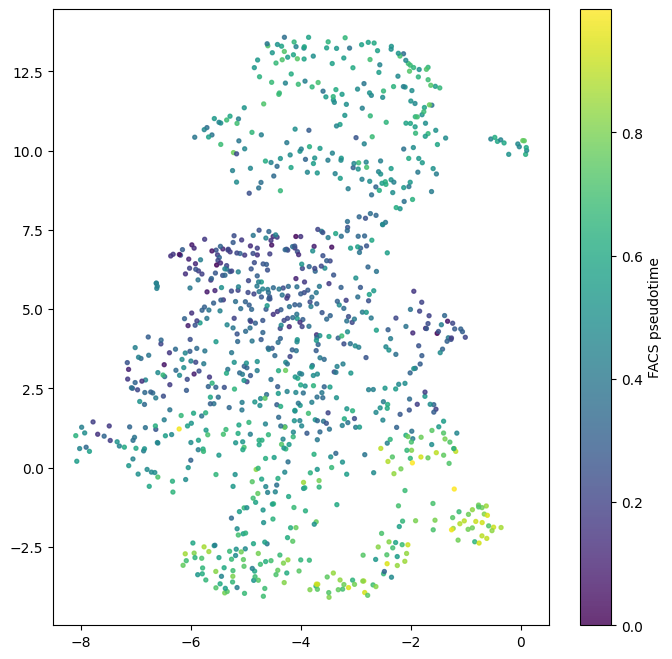

In [16]:
import numpy as np
import matplotlib.pyplot as plt

X_umap = adata.obsm["X_umap"]

pseudo = adata.obs["facs_pseudotime"].values

x, y = X_umap[:, 0], X_umap[:, 1]

x_min, x_max = np.quantile(x, [0.01, 0.99])
y_min, y_max = np.quantile(y, [0.01, 0.99])

mask = (x > x_min) & (x < x_max) & (y > y_min) & (y < y_max)

X_umap_f = X_umap[mask]
V_umap_f = V_umap_smooth[mask]
pseudo_f = pseudo[mask]

fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(
    X_umap_f[:, 0], X_umap_f[:, 1],
    c=pseudo_f,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap_f[sample, 0], X_umap_f[sample, 1],
    V_umap_f[sample, 0], V_umap_f[sample, 1],
    color="black", alpha=0.6, scale=10, width=0.002
)

ax.set_title("Velocity Field on UMAP (Pseudotime-colored)")
plt.show()

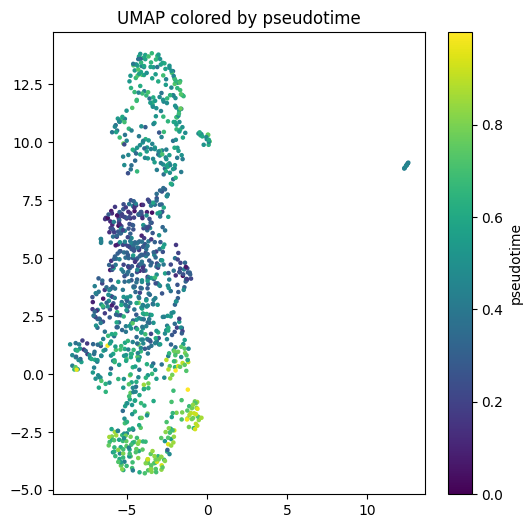

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(X_umap[:,0], X_umap[:,1], c=adata.obs["facs_pseudotime"], s=5)
plt.colorbar(label="pseudotime")
plt.title("UMAP colored by pseudotime")
plt.show()

In [18]:
from scipy.stats import spearmanr

score = spearmanr(
    adata.obs["facs_pseudotime"],
    np.linalg.norm(V_pred, axis=1)
)[0]

print(score)

0.17886410551524795


In [20]:
score = spearmanr(
    adata.obs["facs_pseudotime"],
    (V_pred * X).sum(axis=1)
)[0]
print(score)

-0.2294462012895146


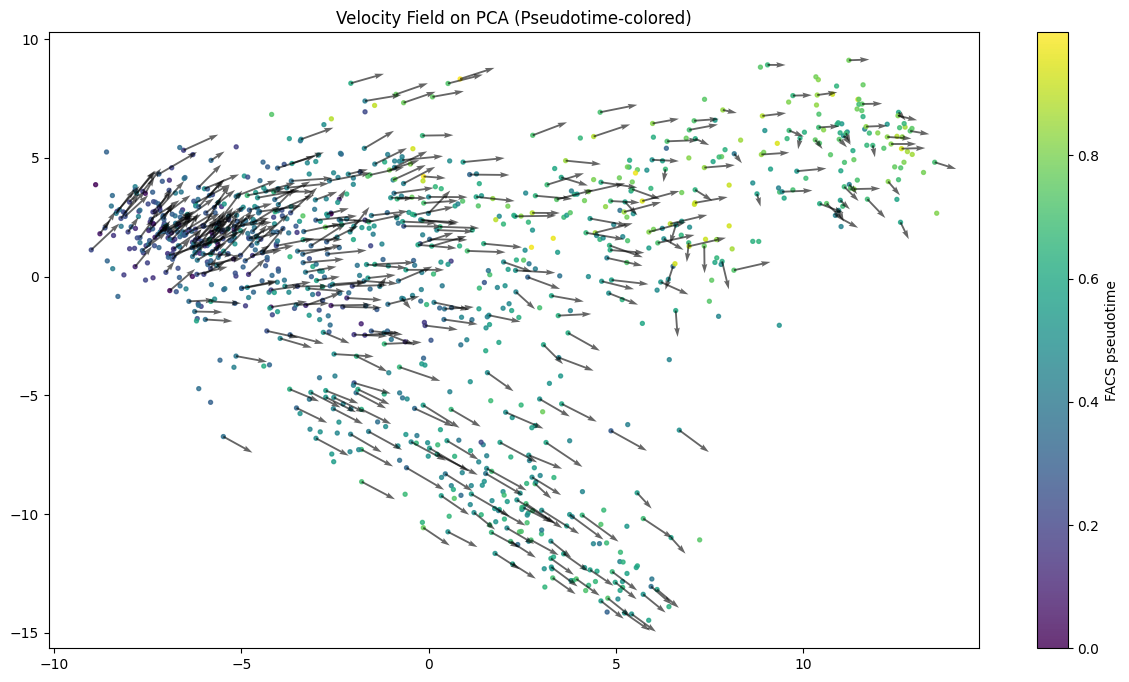

In [29]:
X_pca = adata.obsm["X_pca"][:, :10]  # use first PCs# linear projection of gene velocity into PCA space
V_pca = V_pred @ pca.components_.T[:, :10]
V_pca = -V_pca

from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
_, idx = nn.kneighbors(X_pca)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth = V_pca_smooth / (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)
V_pca_smooth *= 0.5

import numpy as np
import matplotlib.pyplot as plt

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_pca), 400, replace=False)

ax.quiver(
    X_pca[sample, 0], X_pca[sample, 1],
    V_pca_smooth[sample, 0], V_pca_smooth[sample, 1],
    color="black", alpha=0.6, scale=10, width=0.002
)

ax.set_title("Velocity Field on PCA (Pseudotime-colored)")
plt.show()

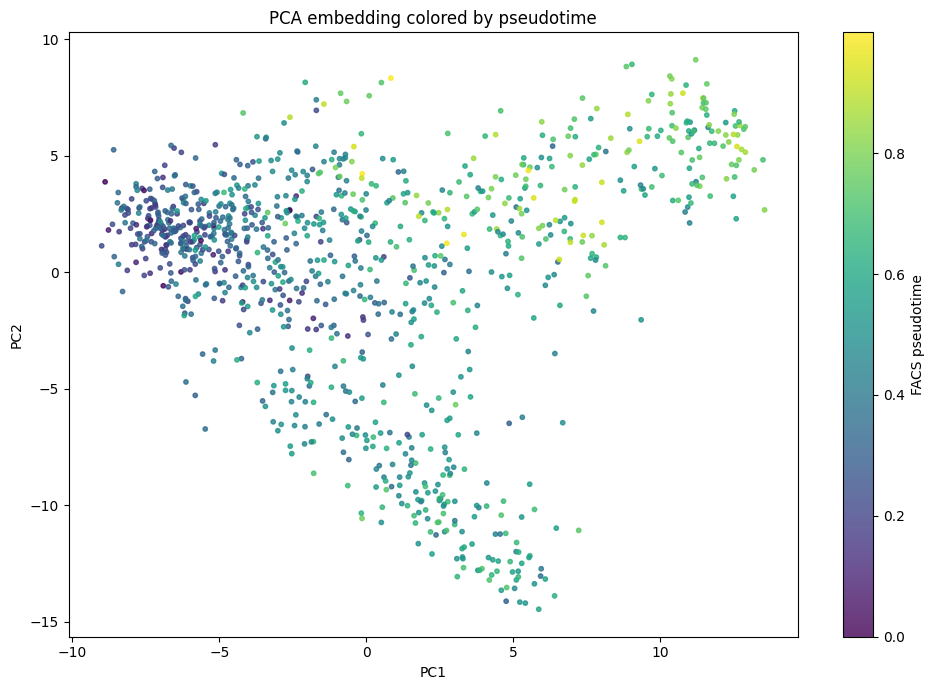

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# PCA embedding
X_pca = adata.obsm["X_pca"][:, :2]

# pseudotime (or swap for any obs label)
pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=10,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA embedding colored by pseudotime")

plt.tight_layout()
plt.show()

In [33]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

N = X.shape[0]

nn = NearestNeighbors(n_neighbors=30).fit(X)
neighbors = nn.kneighbors(X, return_distance=False)

def flow_alignment(V_pred, X, neighbors):
    N = X.shape[0]
    scores = []

    for i in range(N):
        vi = V_pred[i]
        vi_norm = np.linalg.norm(vi) + 1e-8

        for j in neighbors[i]:
            dx = X[j] - X[i]

            score = np.dot(vi, dx) / (
                vi_norm * (np.linalg.norm(dx) + 1e-8)
            )
            scores.append(score)

    return np.mean(scores)

score_forward = flow_alignment(V_pred, X, neighbors)
score_backward = flow_alignment(-V_pred, X, neighbors)

print("forward:", score_forward)
print("backward:", score_backward)

forward: 0.3688337
backward: -0.3688337


In [31]:
score_forward = alignment(V_pred)
score_backward = alignment(-V_pred)

TypeError: 'numpy.ndarray' object is not callable